In [19]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/oneforyash/io-vnbd-dataset/.gitattributes
/kaggle/input/datasets/oneforyash/io-vnbd-dataset/README.md
/kaggle/input/datasets/oneforyash/io-vnbd-dataset/README_1.pdf
/kaggle/input/datasets/oneforyash/io-vnbd-dataset/Synchronised V abd S datasets/Synchronised V abd S datasets/Categorised IOVNB Dataset/M (Driver B)/S-M.csv
/kaggle/input/datasets/oneforyash/io-vnbd-dataset/Synchronised V abd S datasets/Synchronised V abd S datasets/Categorised IOVNB Dataset/M (Driver B)/V-M.JPG
/kaggle/input/datasets/oneforyash/io-vnbd-dataset/Synchronised V abd S datasets/Synchronised V abd S datasets/Categorised IOVNB Dataset/M (Driver B)/V-M.csv
/kaggle/input/datasets/oneforyash/io-vnbd-dataset/Synchronised V abd S datasets/Synchronised V abd S datasets/Categorised IOVNB Dataset/S (Driver A)/S1/S-S1.csv
/kaggle/input/datasets/oneforyash/io-vnbd-dataset/Synchronised V abd S datasets/Synchronised V abd S datasets/Categorised IOVNB Dataset/S (Driver A)/S1/V-S1.JPG
/kaggle/input/datas

In [20]:
import os

for root, dirs, files in os.walk('/kaggle/input/'):
    for file in files:
        if file.endswith('.csv') or file.endswith('.zip'):
            print(os.path.join(root, file))

/kaggle/input/datasets/oneforyash/io-vnbd-dataset/Synchronised V abd S datasets/Synchronised V abd S datasets/Categorised IOVNB Dataset/M (Driver B)/S-M.csv
/kaggle/input/datasets/oneforyash/io-vnbd-dataset/Synchronised V abd S datasets/Synchronised V abd S datasets/Categorised IOVNB Dataset/M (Driver B)/V-M.csv
/kaggle/input/datasets/oneforyash/io-vnbd-dataset/Synchronised V abd S datasets/Synchronised V abd S datasets/Categorised IOVNB Dataset/S (Driver A)/S1/S-S1.csv
/kaggle/input/datasets/oneforyash/io-vnbd-dataset/Synchronised V abd S datasets/Synchronised V abd S datasets/Categorised IOVNB Dataset/S (Driver A)/S1/V-S1.csv
/kaggle/input/datasets/oneforyash/io-vnbd-dataset/Synchronised V abd S datasets/Synchronised V abd S datasets/Categorised IOVNB Dataset/S (Driver A)/S2/S-S2.csv
/kaggle/input/datasets/oneforyash/io-vnbd-dataset/Synchronised V abd S datasets/Synchronised V abd S datasets/Categorised IOVNB Dataset/S (Driver A)/S2/V-S2.csv
/kaggle/input/datasets/oneforyash/io-vnbd-

In [21]:
import pandas as pd

# Exact paths from your output
sensor_path = '/kaggle/input/datasets/oneforyash/io-vnbd-dataset/Synchronised V abd S datasets/Synchronised V abd S datasets/Categorised IOVNB Dataset/M (Driver B)/S-M.csv'
vehicle_path = '/kaggle/input/datasets/oneforyash/io-vnbd-dataset/Synchronised V abd S datasets/Synchronised V abd S datasets/Categorised IOVNB Dataset/M (Driver B)/V-M.csv'

# Load the CSVs
sensor_df = pd.read_csv(sensor_path, encoding='latin1')
vehicle_df = pd.read_csv(vehicle_path)

# Clean column names
sensor_df.columns = sensor_df.columns.str.strip()
vehicle_df.columns = vehicle_df.columns.str.strip()

# Robust renaming
rename_dict = {}
for col in sensor_df.columns:
    if 'ACCELEROMETER X' in col: rename_dict[col] = 'ACCELEROMETER X'
    elif 'ACCELEROMETER Y' in col: rename_dict[col] = 'ACCELEROMETER Y'
    elif 'ACCELEROMETER Z' in col: rename_dict[col] = 'ACCELEROMETER Z'
    elif 'GYROSCOPE Yaw' in col: rename_dict[col] = 'GYROSCOPE Yaw'
    elif 'GYROSCOPE Pitch' in col: rename_dict[col] = 'GYROSCOPE Pitch'
    elif 'GYROSCOPE Roll' in col: rename_dict[col] = 'GYROSCOPE Roll'

sensor_df = sensor_df.rename(columns=rename_dict)

print("Data loaded and columns successfully renamed!")
print(f"Sensor columns: {list(sensor_df.columns[:10])}...")

Data loaded and columns successfully renamed!
Sensor columns: ['GPS LATITUDE (degrees)', 'GPS LONGITUDE (degrees)', 'GPS ALTITUDE (m)', 'GPS SPEED (Kmh)', 'GPS ACCURACY (m)', 'GPS ORIENTATION (Â°)', 'GPS SATELLITES IN RANGE', 'TIME SINCE START (ms)', 'DATE (YYYY-MO-DD HH-MI-SS_SSS)', 'ACCELEROMETER X']...


In [22]:
"""
IO-VNBD preprocessing for a TCN+GRU dead-reckoning model.

Pipeline:
  1. Downsample 100 Hz IMU -> 10 Hz (mean over each 100 ms bin, which acts as an anti-alias filter)
  2. Merge with 10 Hz ground truth on a shared integer tick (1 tick = 100 ms)
  3. Normalize IMU inputs (and velocity target) using TRAIN statistics only
  4. Sliding-window Dataset: X = (50, 6) IMU, Y = [velocity, sin(heading), cos(heading)] at the last step

Usage in a notebook cell:
    from imu_preprocessing import build_datasets
    train_ds, val_ds, test_ds, scaler = build_datasets(sensor_df, vehicle_df)
"""

import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset

# ----------------------------------------------------------------------------
# Column names -- edit here if your DataFrame headers differ slightly
# ----------------------------------------------------------------------------
IMU_TIME_COL = "TIME SINCE START (ms)"
IMU_COLS = [
    "ACCELEROMETER X", "ACCELEROMETER Y", "ACCELEROMETER Z",
    "GYROSCOPE Yaw", "GYROSCOPE Pitch", "GYROSCOPE Roll",
]
GT_TIME_COL = "Time Since Start of Day (seconds)"
VEL_COL = "Velocity (km/hr)"
HEAD_COL = "Heading (degrees)"

TICK_S = 0.1          # 10 Hz
WINDOW = 50           # timesteps per sample (= 5 s at 10 Hz)


# ----------------------------------------------------------------------------
# 1 + 2. Downsample and merge
# ----------------------------------------------------------------------------
def downsample_imu(sensor_df: pd.DataFrame) -> pd.DataFrame:
    """100 Hz -> 10 Hz by averaging all samples in (t-100ms, t]. Returns df indexed by integer tick."""
    t = sensor_df[IMU_TIME_COL].to_numpy(dtype=np.float64) / 1000.0
    df = sensor_df[IMU_COLS].copy()
    df.index = pd.to_timedelta(t, unit="s")
    df = df.sort_index()

    out = df.resample("100ms", label="right", closed="right").mean()
    out["tick"] = np.round(out.index.total_seconds() / TICK_S).astype(np.int64)
    return out.reset_index(drop=True)


def prepare_ground_truth(vehicle_df: pd.DataFrame, time_offset_s: float = 0.0) -> pd.DataFrame:
    """Re-zero ground-truth time to 'since start of recording' and map to integer ticks.

    time_offset_s: seconds by which the IMU recording starts AFTER the first GT sample
    (0 assumes both logs start together). Check this against your data!
    """
    t = vehicle_df[GT_TIME_COL].to_numpy(dtype=np.float64)
    t = t - t[0] - time_offset_s
    gt = vehicle_df[[VEL_COL, HEAD_COL]].copy()
    gt["tick"] = np.round(t / TICK_S).astype(np.int64)
    return gt.drop_duplicates("tick").reset_index(drop=True)


def merge_streams(sensor_df, vehicle_df, time_offset_s: float = 0.0) -> pd.DataFrame:
    imu10 = downsample_imu(sensor_df)
    gt = prepare_ground_truth(vehicle_df, time_offset_s)
    merged = imu10.merge(gt, on="tick", how="inner").sort_values("tick").reset_index(drop=True)

    # Fill tiny gaps (<=2 ticks) in the data; anything bigger is left as a segment break
    cols = IMU_COLS + [VEL_COL, HEAD_COL]
    merged[cols] = merged[cols].interpolate(limit=2, limit_area="inside")
    merged = merged.dropna(subset=cols).reset_index(drop=True)

    # Segment id: increments whenever consecutive ticks are not adjacent, so windows never span a gap
    merged["segment"] = (merged["tick"].diff().fillna(1) != 1).cumsum()
    return merged


# ----------------------------------------------------------------------------
# 3. Normalization (fit on train only to avoid leakage)
# ----------------------------------------------------------------------------
class StandardScaler:
    def __init__(self):
        self.x_mean = self.x_std = None
        self.v_mean = self.v_std = None

    def fit(self, df: pd.DataFrame):
        self.x_mean = df[IMU_COLS].mean().to_numpy(np.float32)
        self.x_std = df[IMU_COLS].std().replace(0, 1.0).to_numpy(np.float32)
        self.v_mean = float(df[VEL_COL].mean())
        self.v_std = float(df[VEL_COL].std() or 1.0)
        return self

    def transform_x(self, arr):
        return (arr - self.x_mean) / (self.x_std + 1e-8)

    def encode_y(self, vel, heading_deg):
        """-> [normalized velocity, sin(heading), cos(heading)]"""
        v = (vel - self.v_mean) / (self.v_std + 1e-8)
        h = np.deg2rad(heading_deg)
        return np.stack([v, np.sin(h), np.cos(h)], axis=-1).astype(np.float32)

    def decode_y(self, y):
        """Model output (N,3) -> (velocity km/h, heading in [0, 360) degrees)."""
        y = np.asarray(y)
        vel = y[..., 0] * self.v_std + self.v_mean
        heading = np.rad2deg(np.arctan2(y[..., 1], y[..., 2])) % 360.0
        return vel, heading


# ----------------------------------------------------------------------------
# 4. Dataset
# ----------------------------------------------------------------------------
class IMUWindowDataset(Dataset):
    """Sliding windows of IMU data. Each item:
        X: (window, 6)  float32   -> transpose to (6, window) for Conv1d/TCN
        Y: (3,)         float32   -> [vel_norm, sin(heading), cos(heading)] at the LAST step of the window
    Windows never cross segment boundaries (time gaps).
    """

    def __init__(self, df: pd.DataFrame, scaler: StandardScaler, window: int = WINDOW, stride: int = 1):
        self.window = window
        self.X = scaler.transform_x(df[IMU_COLS].to_numpy(np.float32)).astype(np.float32)
        self.Y = scaler.encode_y(df[VEL_COL].to_numpy(np.float64), df[HEAD_COL].to_numpy(np.float64))

        # Valid window start indices: window must lie fully inside one segment
        seg = df["segment"].to_numpy()
        starts = []
        for s in np.unique(seg):
            idx = np.flatnonzero(seg == s)
            lo, hi = idx[0], idx[-1]
            starts.extend(range(lo, hi - window + 2, stride))
        self.starts = np.asarray(starts, dtype=np.int64)

    def __len__(self):
        return len(self.starts)

    def __getitem__(self, i):
        s = self.starts[i]
        e = s + self.window
        return torch.from_numpy(self.X[s:e]), torch.from_numpy(self.Y[e - 1])


# ----------------------------------------------------------------------------
# Convenience: chronological split + datasets
# ----------------------------------------------------------------------------
def build_datasets(sensor_df, vehicle_df, time_offset_s=0.0,
                   train_frac=0.7, val_frac=0.15, window=WINDOW, stride=1):
    merged = merge_streams(sensor_df, vehicle_df, time_offset_s)
    n = len(merged)
    i1, i2 = int(n * train_frac), int(n * (train_frac + val_frac))
    train_df, val_df, test_df = merged.iloc[:i1], merged.iloc[i1:i2], merged.iloc[i2:]

    scaler = StandardScaler().fit(train_df)
    mk = lambda d, st: IMUWindowDataset(d, scaler, window, st)
    return mk(train_df, stride), mk(val_df, 1), mk(test_df, 1), scaler


if __name__ == "__main__":
    # In your Kaggle notebook, sensor_df and vehicle_df already exist:
    # from torch.utils.data import DataLoader
    # train_ds, val_ds, test_ds, scaler = build_datasets(sensor_df, vehicle_df)
    # train_dl = DataLoader(train_ds, batch_size=128, shuffle=True, num_workers=2, pin_memory=True)
    # x, y = next(iter(train_dl))      # x: (B, 50, 6), y: (B, 3)
    # x_tcn = x.transpose(1, 2)        # (B, 6, 50) for Conv1d; keep (B, 50, 6) for GRU (batch_first=True)
    pass

In [23]:
import torch
from torch.utils.data import DataLoader

# Build the datasets
train_ds, val_ds, test_ds, scaler = build_datasets(sensor_df, vehicle_df)

# Create DataLoaders
train_dl = DataLoader(train_ds, batch_size=128, shuffle=True, num_workers=2, pin_memory=True)
val_dl = DataLoader(val_ds, batch_size=128, shuffle=False, num_workers=2, pin_memory=True)

print(f"Training windows: {len(train_ds)}")
print(f"Validation windows: {len(val_ds)}")

# Verify the batch shapes
x, y = next(iter(train_dl))
print(f"X shape (Batch, Window, Features): {x.shape}") # Should be (128, 50, 6)
print(f"Y shape (Batch, Targets): {y.shape}")          # Should be (128, 3)

Training windows: 43134
Validation windows: 9215
X shape (Batch, Window, Features): torch.Size([128, 50, 6])
Y shape (Batch, Targets): torch.Size([128, 3])


In [24]:
#  TCN + GRU model and training loop ----
# Assumes train_dl and val_dl already exist 
import copy
import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)


class CausalConv1d(nn.Module):
    """1D dilated convolution padded on the left only, so output at t never sees the future."""
    def __init__(self, in_ch, out_ch, kernel_size, dilation):
        super().__init__()
        self.pad = (kernel_size - 1) * dilation
        self.conv = nn.Conv1d(in_ch, out_ch, kernel_size, dilation=dilation)

    def forward(self, x):                      # x: (B, C, T)
        return self.conv(F.pad(x, (self.pad, 0)))


class TCNBlock(nn.Module):
    """Two dilated causal convs + residual connection."""
    def __init__(self, in_ch, out_ch, kernel_size, dilation, dropout):
        super().__init__()
        self.conv1 = CausalConv1d(in_ch, out_ch, kernel_size, dilation)
        self.conv2 = CausalConv1d(out_ch, out_ch, kernel_size, dilation)
        self.norm1 = nn.GroupNorm(1, out_ch)
        self.norm2 = nn.GroupNorm(1, out_ch)
        self.drop = nn.Dropout(dropout)
        self.res = nn.Conv1d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x):
        out = self.drop(F.relu(self.norm1(self.conv1(x))))
        out = self.drop(F.relu(self.norm2(self.conv2(out))))
        return F.relu(out + self.res(x))


class TCN_GRU(nn.Module):
    def __init__(self, in_features=6, tcn_channels=64, kernel_size=3,
                 dilations=(1, 2, 4, 8), gru_hidden=64, gru_layers=2,
                 dropout=0.2, out_features=3):
        super().__init__()
        blocks, ch = [], in_features
        for d in dilations:
            blocks.append(TCNBlock(ch, tcn_channels, kernel_size, d, dropout))
            ch = tcn_channels
        self.tcn = nn.Sequential(*blocks)       # receptive field = 61 steps with defaults (> 50)
        self.gru = nn.GRU(tcn_channels, gru_hidden, num_layers=gru_layers,
                          batch_first=True, dropout=dropout if gru_layers > 1 else 0.0)
        self.fc = nn.Linear(gru_hidden, out_features)

    def forward(self, x):                       # x: (B, 50, 6)
        x = x.transpose(1, 2)                   # -> (B, 6, 50)
        x = self.tcn(x)                         # -> (B, C, 50)
        x = x.transpose(1, 2)                   # -> (B, 50, C)
        out, _ = self.gru(x)                    # -> (B, 50, H)
        return self.fc(out[:, -1])              # last timestep -> (B, 3)


model = TCN_GRU().to(device)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

EPOCHS = 20
criterion = nn.HuberLoss()                      # swap for nn.MSELoss() if you prefer
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)


def run_epoch(loader, train):
    model.train(train)
    total, n = 0.0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            pred = model(x)
            loss = criterion(pred, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            total += loss.item() * x.size(0)
            n += x.size(0)
    return total / n


best_val, best_state = float('inf'), None
history = {"train": [], "val": []}

for epoch in range(1, EPOCHS + 1):
    tr = run_epoch(train_dl, train=True)
    va = run_epoch(val_dl, train=False)
    history["train"].append(tr)
    history["val"].append(va)
    flag = ""
    if va < best_val:
        best_val, best_state = va, copy.deepcopy(model.state_dict())
        torch.save(best_state, "best_tcn_gru.pt")
        flag = "  <- best"
    print(f"Epoch {epoch:02d}/{EPOCHS} | Train Loss: {tr:.5f} | Val Loss: {va:.5f}{flag}")

model.load_state_dict(best_state)
print(f"\nDone. Best val loss: {best_val:.5f} (weights saved to best_tcn_gru.pt and loaded into `model`)")

Using device: cuda
Trainable parameters: 139,267
Epoch 01/20 | Train Loss: 0.22667 | Val Loss: 0.68397  <- best
Epoch 02/20 | Train Loss: 0.15089 | Val Loss: 0.66856  <- best
Epoch 03/20 | Train Loss: 0.12366 | Val Loss: 0.63638  <- best
Epoch 04/20 | Train Loss: 0.09949 | Val Loss: 0.70216
Epoch 05/20 | Train Loss: 0.08068 | Val Loss: 0.62454  <- best
Epoch 06/20 | Train Loss: 0.06725 | Val Loss: 0.71246
Epoch 07/20 | Train Loss: 0.05634 | Val Loss: 0.64773
Epoch 08/20 | Train Loss: 0.04742 | Val Loss: 0.65112
Epoch 09/20 | Train Loss: 0.04199 | Val Loss: 0.69501
Epoch 10/20 | Train Loss: 0.03713 | Val Loss: 0.66303
Epoch 11/20 | Train Loss: 0.03314 | Val Loss: 0.69464
Epoch 12/20 | Train Loss: 0.02945 | Val Loss: 0.69799
Epoch 13/20 | Train Loss: 0.02753 | Val Loss: 0.63722
Epoch 14/20 | Train Loss: 0.02469 | Val Loss: 0.67222
Epoch 15/20 | Train Loss: 0.02158 | Val Loss: 0.67412
Epoch 16/20 | Train Loss: 0.02188 | Val Loss: 0.71156
Epoch 17/20 | Train Loss: 0.02050 | Val Loss: 0.634

In [33]:
# --- UPDATED TRAINING LOOP WITH REGULARIZATION ---
model = TCN_GRU().to(device)

EPOCHS = 15
criterion = nn.HuberLoss()
# ADDED: weight_decay to prevent overfitting
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-4) 
# ADDED: Scheduler to lower LR if val loss plateaus
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=2, factor=0.5)

def run_epoch(loader, train):
    model.train(train)
    total, n = 0.0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            pred = model(x)
            loss = criterion(pred, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            total += loss.item() * x.size(0)
            n += x.size(0)
    return total / n

best_val, best_state = float('inf'), None
history = {"train": [], "val": []}

for epoch in range(1, EPOCHS + 1):
    tr = run_epoch(train_dl, train=True)
    va = run_epoch(val_dl, train=False)
    history["train"].append(tr)
    history["val"].append(va)
    
    scheduler.step(va) # Step the scheduler
    
    flag = ""
    if va < best_val:
        best_val, best_state = va, copy.deepcopy(model.state_dict())
        torch.save(best_state, "best_tcn_gru.pt")
        flag = "  <- best"
    print(f"Epoch {epoch:02d}/{EPOCHS} | Train Loss: {tr:.5f} | Val Loss: {va:.5f}{flag}")

model.load_state_dict(best_state)
print(f"\nDone. Best val loss: {best_val:.5f}")

Epoch 01/15 | Train Loss: 0.25144 | Val Loss: 0.25762  <- best
Epoch 02/15 | Train Loss: 0.20022 | Val Loss: 0.21743  <- best
Epoch 03/15 | Train Loss: 0.17662 | Val Loss: 0.20103  <- best
Epoch 04/15 | Train Loss: 0.15936 | Val Loss: 0.19663  <- best
Epoch 05/15 | Train Loss: 0.14514 | Val Loss: 0.18179  <- best
Epoch 06/15 | Train Loss: 0.13521 | Val Loss: 0.17375  <- best
Epoch 07/15 | Train Loss: 0.12529 | Val Loss: 0.18560
Epoch 08/15 | Train Loss: 0.11883 | Val Loss: 0.18296
Epoch 09/15 | Train Loss: 0.11221 | Val Loss: 0.16631  <- best
Epoch 10/15 | Train Loss: 0.10588 | Val Loss: 0.16579  <- best
Epoch 11/15 | Train Loss: 0.10093 | Val Loss: 0.16649
Epoch 12/15 | Train Loss: 0.09657 | Val Loss: 0.15887  <- best
Epoch 13/15 | Train Loss: 0.09235 | Val Loss: 0.15951
Epoch 14/15 | Train Loss: 0.08863 | Val Loss: 0.15433  <- best
Epoch 15/15 | Train Loss: 0.08451 | Val Loss: 0.15213  <- best

Done. Best val loss: 0.15213


Evaluating on the unseen Test Set...

--- FINAL METRICS ---
Mean Absolute Error (Speed): 6.72 km/h
Mean Absolute Error (Heading): 92.52 degrees


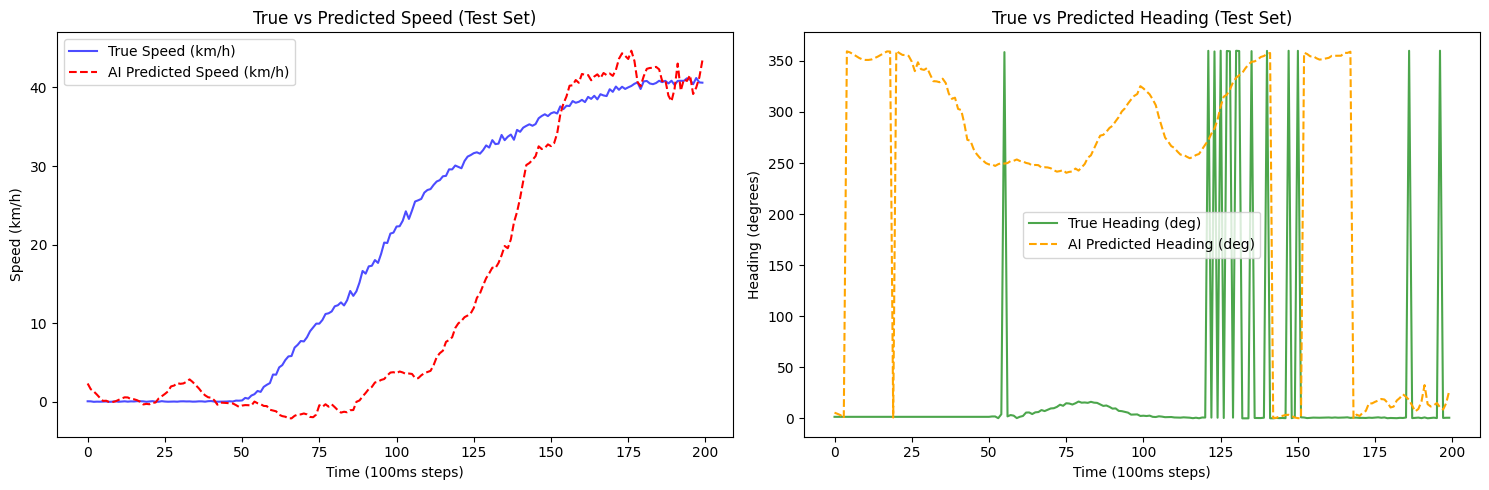

In [34]:
import matplotlib.pyplot as plt
import numpy as np
from torch.utils.data import DataLoader

# 1. Create the missing Test DataLoader
test_dl = DataLoader(test_ds, batch_size=128, shuffle=False, num_workers=2, pin_memory=True)

# 2. Evaluate on Test Set
model.eval()
all_preds = []
all_targets = []

print("Evaluating on the unseen Test Set...")
with torch.no_grad():
    for batch_x, batch_y in test_dl:
        batch_x = batch_x.to(device)
        outputs = model(batch_x)
        all_preds.append(outputs.cpu().numpy())
        all_targets.append(batch_y.numpy())

# Concatenate all batches
preds = np.concatenate(all_preds, axis=0)
targets = np.concatenate(all_targets, axis=0)

# 3. Decode from [vel, sin, cos] back to km/h and degrees
pred_vel, pred_heading = scaler.decode_y(preds)
true_vel, true_heading = scaler.decode_y(targets)

# 4. Calculate Error
mae_vel = np.mean(np.abs(pred_vel - true_vel))
mae_heading = np.mean(np.abs(pred_heading - true_heading))

print("\n--- FINAL METRICS ---")
print(f"Mean Absolute Error (Speed): {mae_vel:.2f} km/h")
print(f"Mean Absolute Error (Heading): {mae_heading:.2f} degrees")

# 5. Plot the first 200 predictions to show the judges visually
plt.figure(figsize=(15, 5))

# Speed Plot
plt.subplot(1, 2, 1)
plt.plot(true_vel[:200], label='True Speed (km/h)', color='blue', alpha=0.7)
plt.plot(pred_vel[:200], label='AI Predicted Speed (km/h)', color='red', linestyle='--')
plt.title('True vs Predicted Speed (Test Set)')
plt.xlabel('Time (100ms steps)')
plt.ylabel('Speed (km/h)')
plt.legend()

# Heading Plot
plt.subplot(1, 2, 2)
plt.plot(true_heading[:200], label='True Heading (deg)', color='green', alpha=0.7)
plt.plot(pred_heading[:200], label='AI Predicted Heading (deg)', color='orange', linestyle='--')
plt.title('True vs Predicted Heading (Test Set)')
plt.xlabel('Time (100ms steps)')
plt.ylabel('Heading (degrees)')
plt.legend()

plt.tight_layout()
plt.show()

In [28]:
import numpy as np
import scipy.signal as signal

# 1. Get the true speed from the vehicle data
gt_speed = vehicle_df['Velocity (km/hr)'].to_numpy()
gt_speed = gt_speed - np.mean(gt_speed) # Remove the mean to compare shapes

# 2. Get the forward acceleration from the IMU
# We'll downsample it to match the vehicle data (10Hz) just for this calculation
imu_time = sensor_df['TIME SINCE START (ms)'].to_numpy() / 1000.0
imu_accel = sensor_df['ACCELEROMETER X'].to_numpy() # Assuming X is forward

# Downsample IMU to 10Hz (every 100ms)
imu_10hz = np.mean(imu_accel[:len(imu_accel)//10*10].reshape(-1, 10), axis=1)
imu_10hz = imu_10hz - np.mean(imu_10hz)

# 3. Cross-correlate to find the lag
# We only look at the first 5000 samples (50 seconds) to find the offset
correlation = signal.correlate(imu_10hz[:5000], gt_speed[:5000], mode='full')
lags = signal.correlation_lags(imu_10hz[:5000].size, gt_speed[:5000].size, mode='full')

# The lag where correlation is highest
best_lag = lags[np.argmax(correlation)]
time_offset_seconds = best_lag * 0.1 # Convert samples to seconds

print(f"Found time offset: {time_offset_seconds:.2f} seconds")

# 4. Rebuild the datasets WITH the time offset!
print("Rebuilding datasets with new offset...")
train_ds, val_ds, test_ds, scaler = build_datasets(sensor_df, vehicle_df, time_offset_s=time_offset_seconds)
train_dl = DataLoader(train_ds, batch_size=128, shuffle=True, num_workers=2, pin_memory=True)
val_dl = DataLoader(val_ds, batch_size=128, shuffle=False, num_workers=2, pin_memory=True)
test_dl = DataLoader(test_ds, batch_size=128, shuffle=False, num_workers=2, pin_memory=True)

print(f"New Training windows: {len(train_ds)}")

Found time offset: -211.80 seconds
Rebuilding datasets with new offset...
New Training windows: 41651


In [31]:
import pandas as pd

# New paths for Driver A, Route S1
sensor_path = '/kaggle/input/datasets/oneforyash/io-vnbd-dataset/Synchronised V abd S datasets/Synchronised V abd S datasets/Categorised IOVNB Dataset/S (Driver A)/S1/S-S1.csv'
vehicle_path = '/kaggle/input/datasets/oneforyash/io-vnbd-dataset/Synchronised V abd S datasets/Synchronised V abd S datasets/Categorised IOVNB Dataset/S (Driver A)/S1/V-S1.csv'

sensor_df = pd.read_csv(sensor_path, encoding='latin1')
vehicle_df = pd.read_csv(vehicle_path)

sensor_df.columns = sensor_df.columns.str.strip()
vehicle_df.columns = vehicle_df.columns.str.strip()

rename_dict = {}
for col in sensor_df.columns:
    if 'ACCELEROMETER X' in col: rename_dict[col] = 'ACCELEROMETER X'
    elif 'ACCELEROMETER Y' in col: rename_dict[col] = 'ACCELEROMETER Y'
    elif 'ACCELEROMETER Z' in col: rename_dict[col] = 'ACCELEROMETER Z'
    elif 'GYROSCOPE Yaw' in col: rename_dict[col] = 'GYROSCOPE Yaw'
    elif 'GYROSCOPE Pitch' in col: rename_dict[col] = 'GYROSCOPE Pitch'
    elif 'GYROSCOPE Roll' in col: rename_dict[col] = 'GYROSCOPE Roll'
sensor_df = sensor_df.rename(columns=rename_dict)

print("S1 Data loaded successfully!")

S1 Data loaded successfully!


In [32]:
from torch.utils.data import DataLoader

# Build datasets with NO time offset
train_ds, val_ds, test_ds, scaler = build_datasets(sensor_df, vehicle_df, time_offset_s=0.0)

train_dl = DataLoader(train_ds, batch_size=128, shuffle=True, num_workers=2, pin_memory=True)
val_dl = DataLoader(val_ds, batch_size=128, shuffle=False, num_workers=2, pin_memory=True)
test_dl = DataLoader(test_ds, batch_size=128, shuffle=False, num_workers=2, pin_memory=True)

print(f"Training windows: {len(train_ds)}")

Training windows: 36152
